<a href="https://colab.research.google.com/github/oliviaberset/2026_remote_sensing/blob/main/RSES_TP3_python_forstudents.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# RSES - Exercise 3

Unsupervised classification in Python
Remote Sensing of Earth Systems - Gregoire Mariethoz

Here, for a change we will use Sentinel-2 images. For now I will just provide you with the image, but in general you can download such images on the Copernicus data space (https://dataspace.copernicus.eu/). You might have to create an account, then use the intuitive interface to find and download a Sentinel-2 image that interests you.

We are going to apply k-means unsupervised classification to this image.
The image we are going to work with is in the Moodle folder, named S2A_OPER_MSI_L1C_TL_SGS__20161012T142009_A006826_T32TLS_crop.zip. It is a zip archive with a .jp2 file for each band. jp2 denotes the jpeg2000 format, which uses wavelets to achieve very high levels of compression.
From this file, we will use load all bands and perform a k-means classification with 12 clusters.
Note that the images in this file are a cropped version of a much larger sentinel-2 image, which makes all calculations faster for this exercise.

In [ ]:
!pip install rasterio scikit-image scikit-learn ipympl matplotlib --quiet

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 519.0/519.0 kB 8.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 35.2 MB/s eta 0:00:00


In [ ]:

# Library for reading and writing raster datasets (e.g., GeoTIFF)
import rasterio

# Fundamental package for numerical computations in Python
import numpy as np

# Provides functions to interact with the operating system (e.g., file paths)
import os
# Plotting library for creating static, animated, and interactive visualizations
import matplotlib.pyplot as plt

# Tools for customizing colormaps and normalization in matplotlib
from matplotlib.colors import ListedColormap, BoundaryNorm

# Machine learning library; used here for clustering (e.g., KMeans)
from sklearn.cluster import KMeans

# Image processing library; used for contrast adjustment and other enhancements
from skimage import exposure


In [ ]:

# If you're working in Google Colab, this enables support for custom widgets (e.g., interactive sliders, maps)
# Comment out this section if you're not using Google Colab
from google.colab import output
output.enable_custom_widget_manager()


In [ ]:
#Point to the directory where the data is stored (or comment this line and upload your files if you work in Google Colab)
#os.chdir(".")
#You can use the folder name "." to point to the same folder as this script

Load the bands of the cropped Sentinel image and convert to floats (the equivalent of doubles in Matlab, we need this conversion because we cannot do calculations with integers)

In [ ]:

# Load Sentinel-2 band 2 (Blue) as a float array
B2 = rasterio.open('S2A_OPER_MSI_L1C_TL_SGS__20161012T142009_A006826_T32TLS_B02_crop.jp2').read(1).astype(float)

# Load Sentinel-2 band 3 (Green) as a float array
B3 = rasterio.open('S2A_OPER_MSI_L1C_TL_SGS__20161012T142009_A006826_T32TLS_B03_crop.jp2').read(1).astype(float)

# Load Sentinel-2 band 4 (Red) as a float array
B4 = rasterio.open('S2A_OPER_MSI_L1C_TL_SGS__20161012T142009_A006826_T32TLS_B04_crop.jp2').read(1).astype(float)

# Load Sentinel-2 band 5 (Vegetation Red Edge) as a float array
B5 = rasterio.open('S2A_OPER_MSI_L1C_TL_SGS__20161012T142009_A006826_T32TLS_B05_crop.jp2').read(1).astype(float)

# Load Sentinel-2 band 6 (Vegetation Red Edge) as a float array
B6 = rasterio.open('S2A_OPER_MSI_L1C_TL_SGS__20161012T142009_A006826_T32TLS_B06_crop.jp2').read(1).astype(float)

# Load Sentinel-2 band 7 (Vegetation Red Edge) as a float array
B7 = rasterio.open('S2A_OPER_MSI_L1C_TL_SGS__20161012T142009_A006826_T32TLS_B07_crop.jp2').read(1).astype(float)

# Load Sentinel-2 band 8 (Near Infrared - NIR) as a float array
NIR = rasterio.open('S2A_OPER_MSI_L1C_TL_SGS__20161012T142009_A006826_T32TLS_B08_crop.jp2').read(1).astype(float)

# Load Sentinel-2 band 11 (Shortwave Infrared - SWIR) as a float array
B11 = rasterio.open('S2A_OPER_MSI_L1C_TL_SGS__20161012T142009_A006826_T32TLS_B11_crop.jp2').read(1).astype(float)



/usr/local/lib/python3.13/dist-packages/rasterio/__init__.py:367: NotGeoreferencedWarning: Dataset has no geotransform, gcps, or rpcs. The identity matrix will be returned.
  dataset = DatasetReader(path, driver=driver, sharing=sharing, thread_safe=thread_safe, **kwargs)


Normalize and adjust the Digital Number values to visualize an RGB image

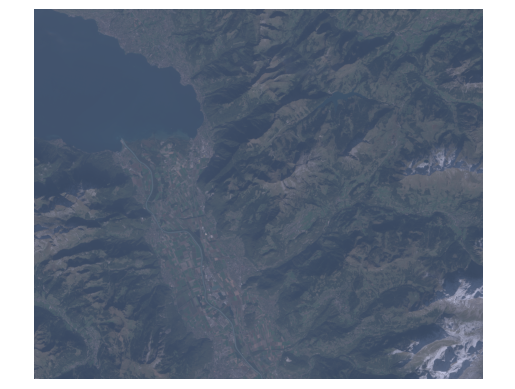

In [ ]:

# Function to normalize an image and apply gamma correction
def normalize_and_adjust(image):
    # Normalize the image by dividing by its maximum value (scales values to [0, 1])
    image = image / image.max()

    # Apply gamma correction to enhance contrast (gamma < 1 brightens the image)
    image = exposure.adjust_gamma(image, gamma=0.3)

    return image

# Apply normalization and gamma correction to the Red, Green, and Blue bands
R_adj = normalize_and_adjust(B4)  # Red band
G_adj = normalize_and_adjust(B3)  # Green band
B_adj = normalize_and_adjust(B2)  # Blue band

# Stack the adjusted bands into a single RGB image
RGB = np.dstack((R_adj, G_adj, B_adj))

# Display the RGB image using matplotlib
plt.figure()
plt.imshow(RGB)        # Show the image
plt.axis('equal')      # Ensure equal aspect ratio
plt.axis('off')        # Hide axis ticks and labels
plt.show()             # Render the image


B5 is at a 20m resolution. Downscale it to match the resolution of bands 2, 3 and 4 (10m).
This is done by simply copying the large value 4 times on the sub-pixels


In [ ]:
# Function to downscale a band to match a target shape by duplicating each pixel into a 2x2 block
def downscale(band, target_shape):
    # Create an empty array with the target shape
    downscaled = np.zeros(target_shape)

    # Fill the array by repeating each pixel value in a 2x2 block
    downscaled[::2, ::2] = band       # Top-left of each block
    downscaled[::2, 1::2] = band      # Top-right
    downscaled[1::2, ::2] = band      # Bottom-left
    downscaled[1::2, 1::2] = band     # Bottom-right

    return downscaled

# Define the target shape based on the NIR band (assumed to be the highest resolution)
target_shape = NIR.shape

# Downscale bands B11, B5, B6, and B7 to match the resolution of the NIR band
B11_downscaled = downscale(B11, target_shape)
B5_downscaled = downscale(B5, target_shape)
B6_downscaled = downscale(B6, target_shape)
B7_downscaled = downscale(B7, target_shape)

Calculate indices

In [ ]:
# YOU HAVE TO WORK HERE
# Compute indices
# Here, compute variables called NDVI, NDWI and NDSI using the appropriate formulas

# NDVI = (NIR - R) / (NIR + R)
# NDWI = (GREEN - NIR) / (GREEN + NIR)
# NDSI = (R - SWIR)/(R+SWIR)

NDVI = (NIR - B4) / (NIR + B4)
NDWI = (B3 - NIR) / (B3 + NIR)
NDSI = (B4 - B11_downscaled) / (B4 + B11_downscaled)

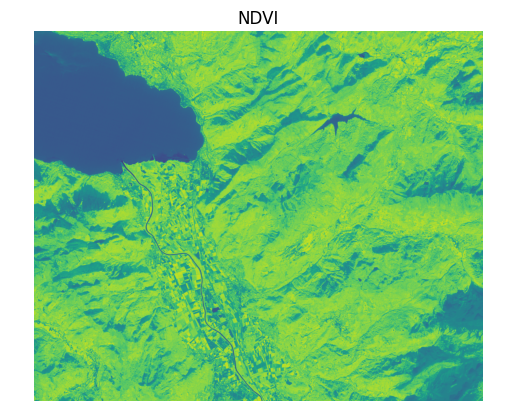

In [ ]:
# YOU HAVE TO WORK HERE
# Show indices
# Here, show maps of the indices NDVI, NDWI and NDSI

NDVI = (NIR - B4) / (NIR + B4)

plt.figure()
plt.imshow(NDVI)        # Show the image
plt.axis('equal')      # Ensure equal aspect ratio
plt.axis('off')        # Hide axis ticks and labels
plt.title("NDVI")
plt.show()

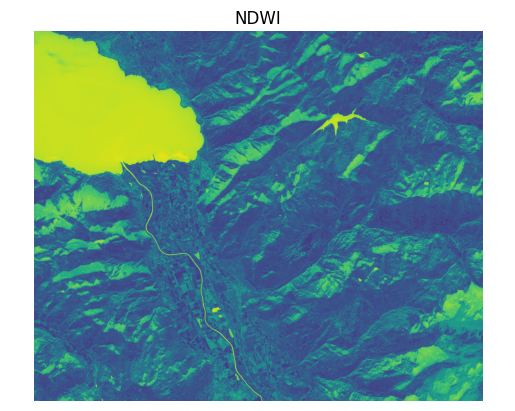

In [ ]:
NDWI = (B3 - NIR) / (B3 + NIR)

plt.figure()
plt.imshow(NDWI)        # Show the image
plt.axis('equal')      # Ensure equal aspect ratio
plt.axis('off')        # Hide axis ticks and labels
plt.title("NDWI")
plt.show()

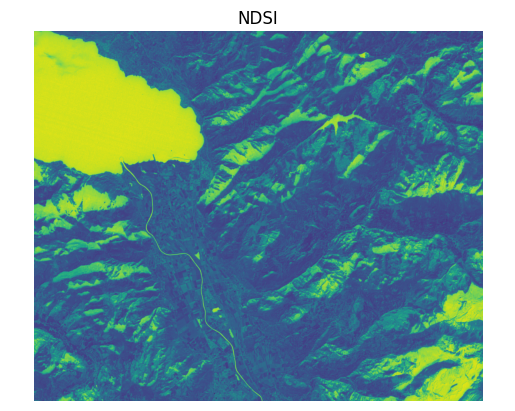

In [ ]:
NDSI = (B4 - B11_downscaled) / (B4 + B11_downscaled)

plt.figure()
plt.imshow(NDSI)        # Show the image
plt.axis('equal')      # Ensure equal aspect ratio
plt.axis('off')        # Hide axis ticks and labels
plt.title("NDSI")
plt.show()             # Render the image

Use the indices to classify lakes, plants and snow

In [ ]:
# YOU HAVE TO WORK HERE
# Here, classify and visualize lakes, plants, and snow by using the following thresholds:
# lakes: NDWI > 0.4
# plants: NDVI > 0.5
# snow: NDSI > 0.7, excluding lakes and plants


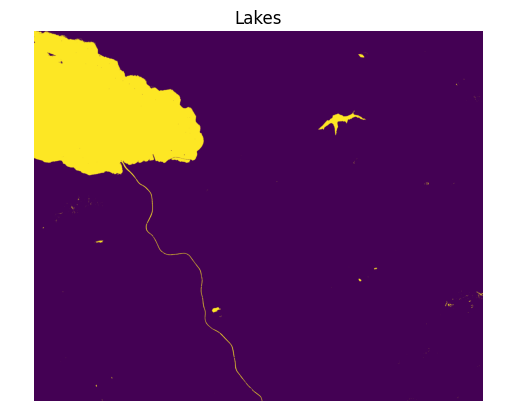

In [ ]:
# lakes: NDWI > 0.4

NDWI = (B3 - NIR) / (B3 + NIR)
NDWI_04 = NDWI > 0.4

plt.figure()
plt.imshow(NDWI_04)        # Show the image
plt.axis('equal')      # Ensure equal aspect ratio
plt.axis('off')        # Hide axis ticks and labels
plt.title("Lakes")
plt.show()

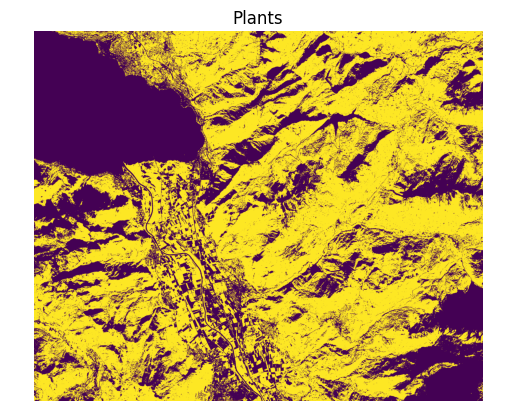

In [ ]:
# plants: NDVI > 0.5

NDVI = (NIR - B4) / (NIR + B4)
NDVI_05 = NDVI > 0.5

plt.figure()
plt.imshow(NDVI_05)        # Show the image
plt.axis('equal')      # Ensure equal aspect ratio
plt.axis('off')        # Hide axis ticks and labels
plt.title("Plants")
plt.show()

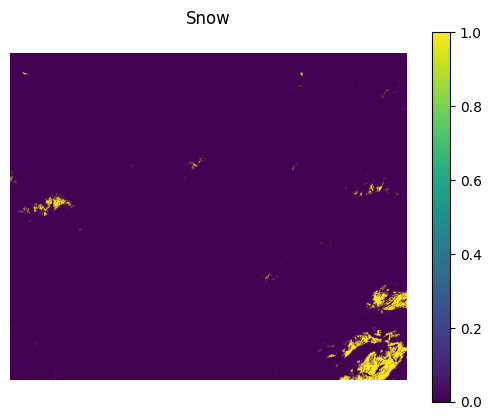

In [ ]:
# snow: NDSI > 0.7, excluding lakes and plants

NDSI = (B4 - B11_downscaled) / (B4 + B11_downscaled)
NDSI_07 = (NDSI > 0.7) & (~NDWI_04) & (~NDVI_05)

plt.figure()
plt.imshow(NDSI_07)    # Show the image
plt.axis('equal')      # Ensure equal aspect ratio
plt.axis('off')        # Hide axis ticks and labels
plt.title("Snow")
plt.colorbar()
plt.show()             # Render the image

In [ ]:
# YOU HAVE TO WORK HERE

# Calculate the number of pixels classified as snow
NbPixelsSnow = np.sum(NDSI_07)

# Calculate the percentage of the total area covered by snow
SnowPercentage = NbPixelsSnow / NDSI_07.size

# Estimate the surface area covered by snow in square kilometers
SnowSurface = NbPixelsSnow * 10 * 10 / 1_000_000

# Print the results
print('_________________________________________')
print('Surface of snow cover over the entire area (km^2):')
print(SnowSurface)
print('Percentage of area covered by snow (%):')
print(SnowPercentage * 100)

_________________________________________
Surface of snow cover over the entire area (km^2):
11.285
Percentage of area covered by snow (%):
1.4634557526714391


Now trying with a K-means classification

Put all bands in a single matrix, adding NDVI in the mix
We will use the KMeans function of the Scikit-learn package

In [ ]:
# Stack all relevant bands and indices into a single multi-dimensional array
# Each pixel will have a feature vector composed of its values in each band
AllBands = np.stack([
    B2, B3, B4,
    B5_downscaled, B6_downscaled, B7_downscaled,
    NIR, B11_downscaled, NDVI
], axis=-1)

# Reshape the 3D array into a 2D array where each row is a pixel and each column is a feature
AllBands = AllBands.reshape(-1, AllBands.shape[-1])

# Apply K-means clustering to classify pixels into 12 groups
# max_iter=6 limits the number of iterations for convergence
kmeans = KMeans(n_clusters=12, max_iter=6)

# Fit the model and predict cluster labels for each pixel
class_labels = kmeans.fit_predict(AllBands)

# Reshape the flat label array back to the original image shape
class_labels = class_labels.reshape(NIR.shape)

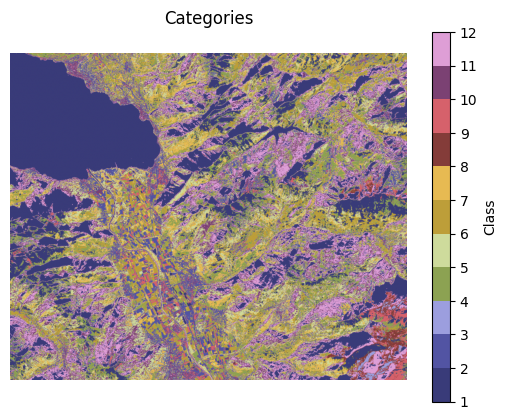

In [ ]:
# Visualize the K-means classification results
# Choose a categorical colormap with 12 distinct colors
# 'tab20b' is a good choice for qualitative data; resampled to match 12 clusters
cmap = plt.colormaps['tab20b'].resampled(12)

# Create a normalization object to map class labels (1 to 12) to colormap indices
norm = BoundaryNorm(np.arange(1, 13), cmap.N)

# Create a new figure for the classification map
plt.figure()

# Display the classified image using the chosen colormap and normalization
plt.imshow(class_labels, cmap=cmap, norm=norm)

# Add a colorbar with ticks and boundaries for each class
plt.colorbar(
    ticks=np.arange(1, 13),           # Tick marks for each class
    boundaries=np.arange(13),         # Boundaries between classes
    label='Class'                     # Label for the colorbar
)

# Add title and formatting
plt.title('Categories')
plt.axis('equal')                     # Keep aspect ratio equal
plt.axis('off')                       # Hide axis ticks and labels
plt.show()                            # Render the plot

We can use boolean operators to combine classes


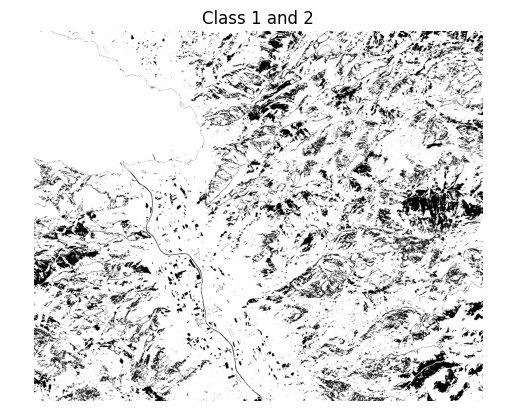

In [ ]:
# Combine class labels 1 and 2 into a single binary mask
# This creates a boolean array where pixels belonging to class 1 or 2 are marked as True
classes12 = (class_labels == 1) | (class_labels == 2)

# Visualize the combined classes
plt.figure()
plt.imshow(classes12, cmap='Greys')   # Display the mask in grayscale
plt.title('Class 1 and 2')            # Title for the plot
plt.axis('equal')                     # Keep aspect ratio equal
plt.axis('off')                       # Hide axis ticks and labels
plt.show()                            # Render the plot